In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("Data")
FILES = {
    "neighborhoods": "Neighborhoods.csv",
    "bridges": "Bridges.csv",
    "crimes": "Crimes.csv",
    "facilities": "Facilities.csv",
    "stops": "Busses.csv",
}

# Equal weights (must add up to 1). Change these to emphasize a metric.
WEIGHTS = {"bridges": 0.25, "transit": 0.25, "facilities": 0.25, "crime": 0.25}

# Names that differ between datasets -> how they appear after cleaning
NAME_FIXES = {"mount oliver": "mt. oliver"}

In [2]:
def clean(s):
    """Stripped, lowercase, en-dash -> hyphen, so names match across files."""
    return (s.astype(str).str.replace("\u2013", "-", regex=False)
             .str.strip().str.lower().replace(NAME_FIXES))


def read(key, **kw):
    return pd.read_csv(DATA_DIR / FILES[key], **kw)

In [3]:
hoods_df = read("neighborhoods")
names = hoods_df["hood"].dropna().unique().tolist()      # official neighborhood names
keys = clean(pd.Series(names))                            # matching keys
by_key = lambda s: s.reindex(keys, fill_value=0).set_axis(names)

# Area (square miles), used to turn crime counts into a rate
area = hoods_df.assign(k=clean(hoods_df["hood"])).groupby("k")["sqmiles"].sum()
area = area.reindex(keys).set_axis(names)

# Bridges: number of bridges per neighborhood
bridges = by_key(clean(read("bridges")["neighborhood"]).value_counts())

# Facilities: number of facilities per neighborhood (all types)
facilities = by_key(clean(read("facilities")["neighborhood"]).value_counts())

# Crime: reported crimes per neighborhood, then per square mile
crimes = by_key(clean(read("crimes", low_memory=False)["Neighborhood"]).value_counts())
crime_rate = crimes / area

# Transit: total weekday trips at all stops in each neighborhood (city stops only)
stops = read("stops", low_memory=False)
stops = stops[stops["muni"].astype(str).str.contains("Pittsburgh")]
transit = stops.assign(k=clean(stops["hood"])).groupby("k")["trips_wd"].sum()
# The stops file lumps two neighborhoods together; give both the combined total.
combo = "arlington-arlington heights"
if combo in transit.index:
    total = transit.pop(combo)
    for k in ("arlington", "arlington heights"):
        transit[k] = transit.get(k, 0) + total
transit = by_key(transit)

metrics = pd.DataFrame({
    "bridges": bridges,
    "transit": transit,
    "facilities": facilities,
    "crime": crime_rate,
})

In [4]:
def to_unit_scale(s, method="percentile"):
    if method == "percentile":
        return s.rank(pct=True)
    s = np.log1p(s)                     
    if method == "minmax":
        return (s - s.min()) / (s.max() - s.min())
    if method == "zscore":
        return (s - s.mean()) / s.std()
    raise ValueError(method)


def score_neighborhoods(df, weights=WEIGHTS, method="percentile"):
    assert abs(sum(weights.values()) - 1) < 1e-9, "weights must sum to 1"
    scaled = pd.DataFrame(index=df.index)
    for col in ["bridges", "transit", "facilities"]:          # higher is better
        scaled[col] = to_unit_scale(df[col], method)
    u = to_unit_scale(df["crime"], method)                    # lower is better: flip
    scaled["crime"] = -u if method == "zscore" else 1 - u
    scaled["score"] = sum(scaled[c] * w for c, w in weights.items())
    return scaled.sort_values("score", ascending=False)


ranked = score_neighborhoods(metrics)

In [5]:
best = ranked.index[0]
print(f"Best neighborhood: {best}  (score {ranked['score'].iloc[0]:.2f})")

Best neighborhood: Squirrel Hill South  (score 0.91)


In [6]:
top5 = ranked.head(5).round(2).reset_index().rename(columns={"index": "Neighborhood"})
top5.columns = ["Neighborhood", "Bridges", "Transit", "Facilities", "Low Crime", "Score"]
top5.index = range(1, 6)
top5.index.name = "Rank"
top5

,Neighborhood,Bridges,Transit,Facilities,Low Crime,Score
Rank,,,,,,
1,Squirrel Hill South,1.00,0.92,0.99,0.71,0.91
2,Squirrel Hill North,0.71,0.98,0.81,0.79,0.82
3,Hazelwood,0.88,0.74,0.94,0.64,0.80
4,Lincoln-Lemington-Belmar,0.71,0.90,0.90,0.66,0.79
5,Highland Park,0.71,0.60,1.00,0.77,0.77


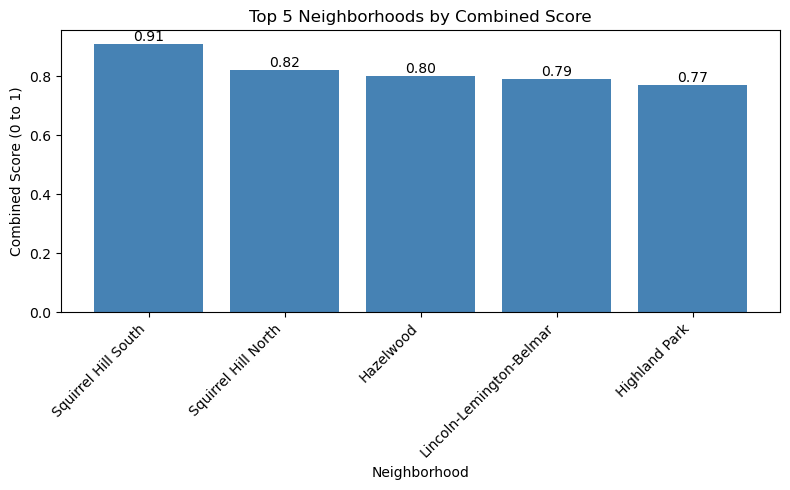

In [9]:
plt.figure(figsize=(8, 5))
plt.bar(top5["Neighborhood"], top5["Score"], color="steelblue")
for i, v in enumerate(top5["Score"]):
    plt.text(i, v, f"{v:.2f}", ha="center", va="bottom")
plt.title("Top 5 Neighborhoods by Combined Score")
plt.xlabel("Neighborhood")
plt.ylabel("Combined Score (0 to 1)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()